In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io as sio

# Load the UMIST dataset
data = sio.loadmat("umist_cropped.mat")

# Check the dataset structure
print("Dataset keys:", data.keys())

Dataset keys: dict_keys(['__header__', '__version__', '__globals__', 'facedat', 'dirnames'])


In [6]:
# Extract the face data
faces = data["facedat"][0]

# Check the number of people
print("Number of people:", len(faces))

# Check the shape of the first person's images
print("First person's image shape:", faces[0].shape)

# Check the total number of images
total_images = sum(person.shape[2] for person in faces)
print("Total number of images:", total_images)

Number of people: 20
First person's image shape: (112, 92, 38)
Total number of images: 575


In [7]:
# Create lists to store images and labels
images = []
labels = []

# Extract images for each person
for person_id, person_faces in enumerate(faces):
    for image_index in range(person_faces.shape[2]):
        image = person_faces[:, :, image_index]

        # Convert the 2D image into a 1D array
        images.append(image.flatten())

        # Assign a label to each person
        labels.append(person_id + 1)

# Convert images into a Pandas DataFrame
df = pd.DataFrame(images)

# Add person labels
df["label"] = labels

# Display dataset information
print("DataFrame shape:", df.shape)
print("Total images:", len(df))
print("Number of unique people:", df["label"].nunique())

# Display first 5 rows
display(df.head())

DataFrame shape: (575, 10305)
Total images: 575
Number of unique people: 20


,0,1,2,3,4,5,6,7,8,9,...,10295,10296,10297,10298,10299,10300,10301,10302,10303,label
0,233,234,234,233,234,232,232,168,99,78,...,154,151,147,143,140,141,141,140,136,1
1,234,234,234,234,233,232,202,98,79,77,...,154,150,147,141,140,137,138,137,137,1
2,234,234,234,234,233,230,225,109,85,84,...,174,168,164,157,152,151,148,145,145,1
3,234,234,234,234,234,234,234,232,229,205,...,168,162,157,155,150,144,144,142,143,1
4,234,234,234,234,234,234,234,234,229,211,...,176,170,164,162,157,152,150,148,148,1


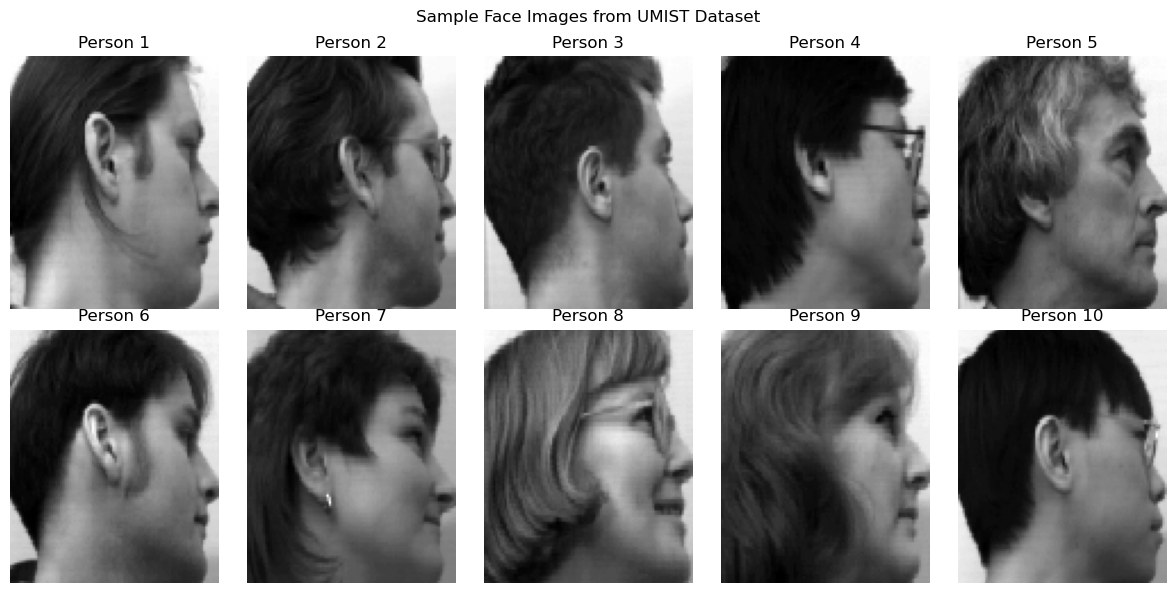

In [8]:
# Display sample face images from the UMIST dataset
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    # Select the first image of each person
    image = faces[i][:, :, 0]

    # Display the face image
    ax.imshow(image, cmap="gray")

    # Add the person's label
    ax.set_title(f"Person {i + 1}")
    ax.axis("off")

plt.suptitle("Sample Face Images from UMIST Dataset")
plt.tight_layout()
plt.show()

In [9]:
from sklearn.model_selection import train_test_split

# Separate image pixels and person labels
X = df.drop(columns=["label"])
y = df["label"]

# First split: 70% training, 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=36
)

# Second split: 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=36
)

# Display dataset sizes
print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

print("\nTraining percentage:", round(len(X_train) / len(df) * 100, 2))
print("Validation percentage:", round(len(X_val) / len(df) * 100, 2))
print("Testing percentage:", round(len(X_test) / len(df) * 100, 2))

Training images: 402
Validation images: 86
Testing images: 87

Training percentage: 69.91
Validation percentage: 14.96
Testing percentage: 15.13


In [10]:
from sklearn.preprocessing import MinMaxScaler

# Create a MinMaxScaler
scaler = MinMaxScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Use the same scaler for validation and test data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Check the scaled data
print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nTraining minimum:", X_train_scaled.min())
print("Training maximum:", X_train_scaled.max())

Training shape: (402, 10304)
Validation shape: (86, 10304)
Testing shape: (87, 10304)

Training minimum: 0.0
Training maximum: 1.0000000000000002


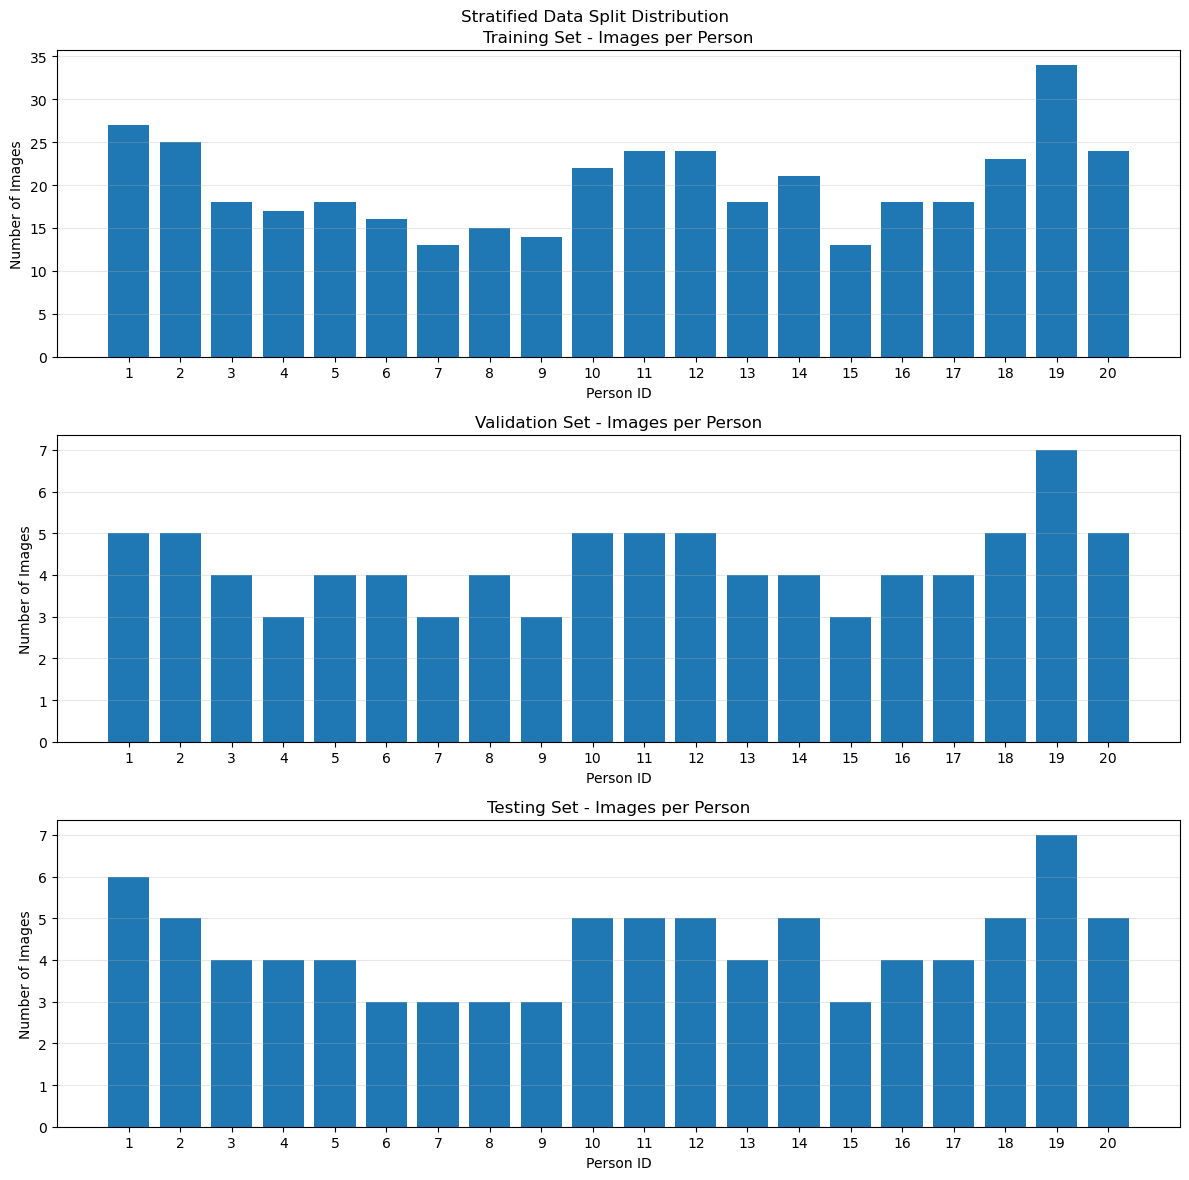

In [11]:
# Count images for each person in each dataset
train_counts = y_train.value_counts().sort_index()
val_counts = y_val.value_counts().sort_index()
test_counts = y_test.value_counts().sort_index()

# Create three distribution graphs
fig, axes = plt.subplots(3, 1, figsize=(12, 12))

datasets = [
    ("Training Set", train_counts),
    ("Validation Set", val_counts),
    ("Testing Set", test_counts)
]

for ax, (title, counts) in zip(axes, datasets):
    ax.bar(counts.index, counts.values)
    ax.set_title(f"{title} - Images per Person")
    ax.set_xlabel("Person ID")
    ax.set_ylabel("Number of Images")
    ax.set_xticks(range(1, 21))
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Stratified Data Split Distribution")
plt.tight_layout()

# Save the figure for the project report
plt.savefig("data_split_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [12]:
from sklearn.decomposition import PCA

# Test different numbers of PCA components
component_options = [10, 20, 50, 100]
explained_variances = []

for n in component_options:
    # Create PCA model
    pca = PCA(n_components=n, svd_solver="randomized",
              random_state=42)

    # Fit PCA only on training data
    pca.fit(X_train_scaled)

    # Calculate total explained variance
    total_variance = pca.explained_variance_ratio_.sum()
    explained_variances.append(total_variance)

    print(f"{n} components: {total_variance * 100:.2f}% explained variance")

10 components: 67.08% explained variance
20 components: 78.87% explained variance
50 components: 89.79% explained variance
100 components: 95.09% explained variance


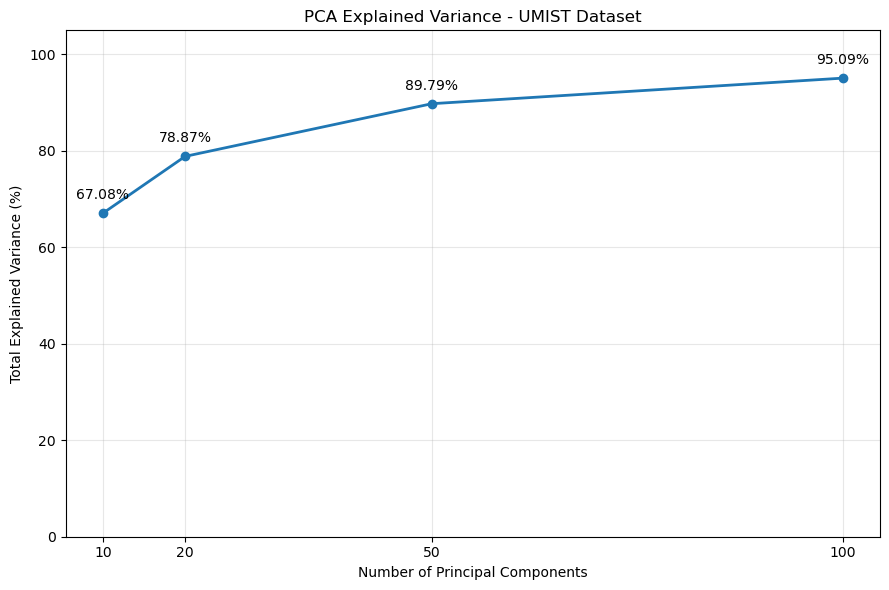

In [13]:
# Plot PCA explained variance
plt.figure(figsize=(9, 6))

plt.plot(
    component_options,
    np.array(explained_variances) * 100,
    marker="o",
    linewidth=2
)

# Add percentage labels
for n, variance in zip(component_options, explained_variances):
    plt.annotate(
        f"{variance * 100:.2f}%",
        (n, variance * 100),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

plt.title("PCA Explained Variance - UMIST Dataset")
plt.xlabel("Number of Principal Components")
plt.ylabel("Total Explained Variance (%)")
plt.xticks(component_options)
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save graph for final report
plt.savefig("pca_explained_variance.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [14]:
from sklearn.decomposition import PCA

# Select 100 PCA components
pca_final = PCA(
    n_components=100,
    svd_solver="randomized",
    random_state=36
)

# Fit PCA only on the training data
X_train_pca = pca_final.fit_transform(X_train_scaled)

# Transform validation and testing data
# using the same fitted PCA model
X_val_pca = pca_final.transform(X_val_scaled)
X_test_pca = pca_final.transform(X_test_scaled)

# Display the new dataset shapes
print("Training PCA shape:", X_train_pca.shape)
print("Validation PCA shape:", X_val_pca.shape)
print("Testing PCA shape:", X_test_pca.shape)

# Check total explained variance
print(
    "\nTotal explained variance:",
    round(
        pca_final.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

Training PCA shape: (402, 100)
Validation PCA shape: (86, 100)
Testing PCA shape: (87, 100)

Total explained variance: 95.09 %


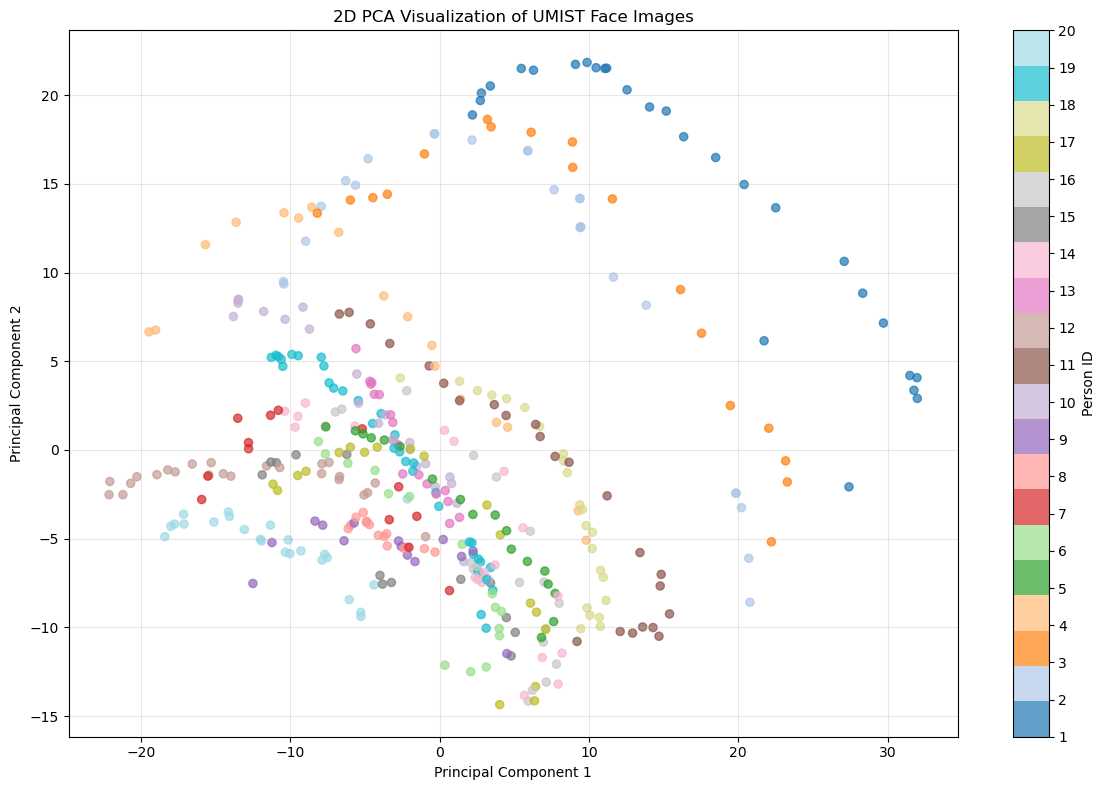

In [15]:
# Create a 2D PCA visualization using training data
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train.to_numpy(),
    cmap="tab20",
    s=35,
    alpha=0.7
)

# Add labels and title
plt.title("2D PCA Visualization of UMIST Face Images")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

# Add colorbar showing person labels
cbar = plt.colorbar(scatter, ticks=range(1, 21))
cbar.set_label("Person ID")

plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the figure for the final report
plt.savefig(
    "pca_2d_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
import numpy as np
import joblib

# Save normalized datasets and labels
np.savez_compressed(
    "umist_preprocessed_data.npz",
    X_train=X_train_scaled,
    X_val=X_val_scaled,
    X_test=X_test_scaled,
    y_train=y_train.to_numpy(),
    y_val=y_val.to_numpy(),
    y_test=y_test.to_numpy()
)

# Save PCA-reduced datasets and labels
np.savez_compressed(
    "umist_pca_data.npz",
    X_train_pca=X_train_pca,
    X_val_pca=X_val_pca,
    X_test_pca=X_test_pca,
    y_train=y_train.to_numpy(),
    y_val=y_val.to_numpy(),
    y_test=y_test.to_numpy()
)

# Save fitted scaler and PCA model
joblib.dump(scaler, "umist_scaler.pkl")
joblib.dump(pca_final, "umist_pca_model.pkl")


['umist_pca_model.pkl']

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Store the values we test
#Testing from k values 2-30
k_values = range(2, 31)

# Store the results
inertia_scores = []
silhouette_scores = []

print("Testing K-Means Clustering")
print("=" * 60)

for k in k_values:

    # Create the K-Means model
    kmeans = KMeans(
        n_clusters=k,
        random_state=36,
        n_init=10
    )

    # Train the model and get cluster assignments
    cluster_labels = kmeans.fit_predict(X_train_pca)

    # Inertia measures how close observations are
    # to their assigned cluster centroid
    inertia = kmeans.inertia_

    # Silhouette measures cluster compactness
    # and separation
    silhouette = silhouette_score(X_train_pca, cluster_labels)

    # Save results
    inertia_scores.append(inertia)
    silhouette_scores.append(silhouette)

    print(f"k = {k:2d} | "f"Inertia = {inertia:10.2f} | "f"Silhouette = {silhouette:.4f}")

Testing K-Means Clustering


c:\Users\Raiha\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Raiha\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Raiha\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Raiha\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

k =  2 | Inertia =  162421.97 | Silhouette = 0.1360
k =  3 | Inertia =  145062.72 | Silhouette = 0.1423
k =  4 | Inertia =  134541.71 | Silhouette = 0.1237


c:\Users\Raiha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Raiha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Raiha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


k =  5 | Inertia =  125766.22 | Silhouette = 0.1394
k =  6 | Inertia =  119157.88 | Silhouette = 0.1393
k =  7 | Inertia =  113572.05 | Silhouette = 0.1333


c:\Users\Raiha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Raiha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Raiha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


... (33 outputs left out)

c:\Users\Raiha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


k = 29 | Inertia =   60945.63 | Silhouette = 0.2361


c:\Users\Raiha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


k = 30 | Inertia =   58856.31 | Silhouette = 0.2439


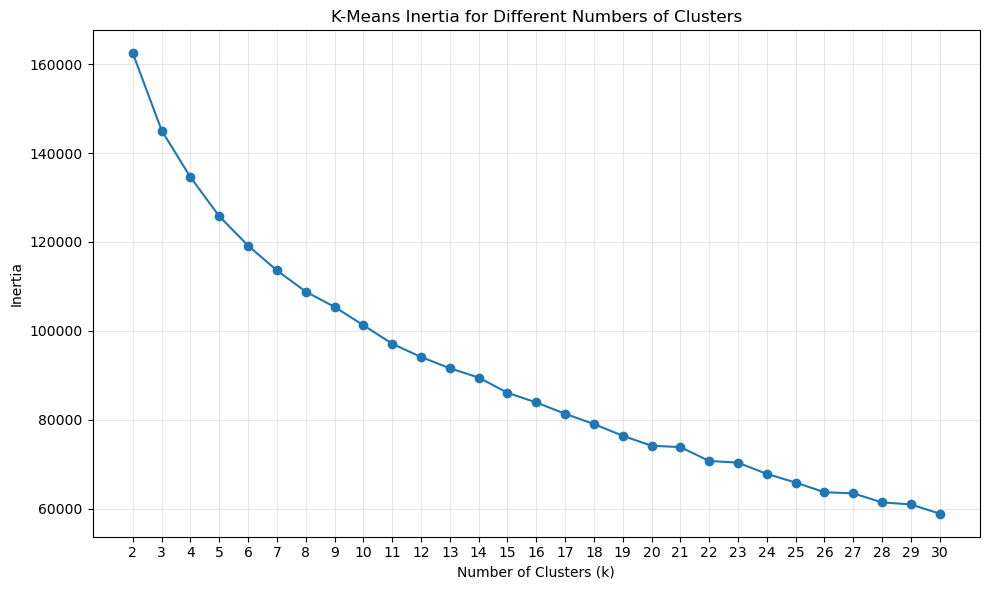

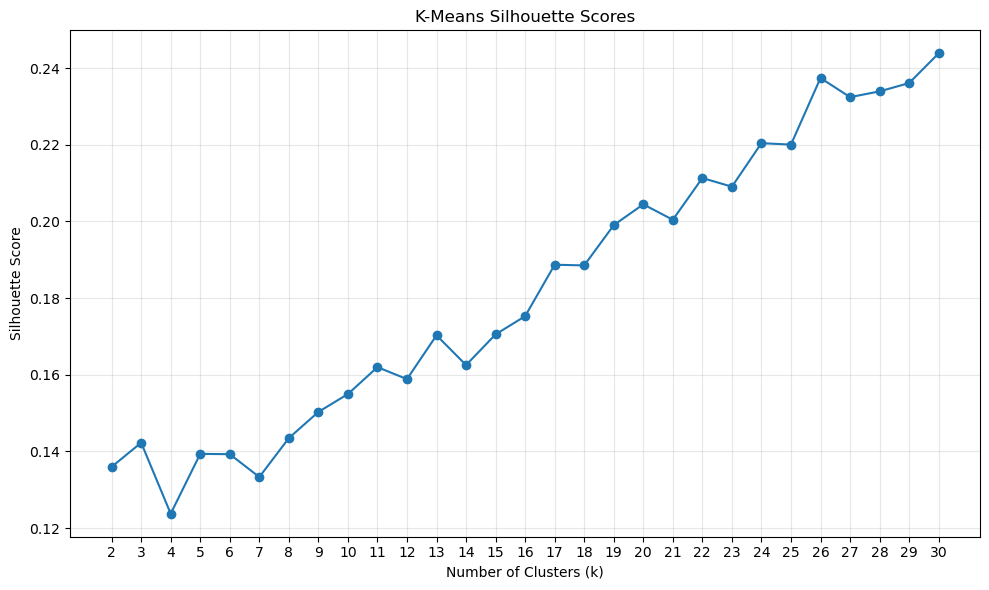

In [18]:
plt.figure(figsize=(10, 6))

plt.plot(list(k_values), inertia_scores, marker="o")

plt.title("K-Means Inertia for Different Numbers of Clusters")

plt.xlabel("Number of Clusters (k)")

plt.ylabel("Inertia")

plt.xticks(list(k_values))

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "kmeans_inertia.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



#Silhouette Plot
plt.figure(figsize=(10, 6))

plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.title("K-Means Silhouette Scores")

plt.xlabel("Number of Clusters (k)")

plt.ylabel("Silhouette Score")

plt.xticks(list(k_values))

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "kmeans_silhouette_scores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
best_index = np.argmax(silhouette_scores)

# Get the corresponding k
best_k = list(k_values)[best_index]

best_silhouette = silhouette_scores[best_index]

print("Best number of clusters:", best_k)

#print highet silhoutee score to 4 decimal places 
print("Highest silhouette score:",round(best_silhouette, 4))

Best number of clusters: 30
Highest silhouette score: 0.2439


In [20]:
best_kmeans = KMeans(
    n_clusters=best_k,
    random_state=36,
    n_init=10
)

kmeans_labels = best_kmeans.fit_predict(
    X_train_pca
)

print(
    "Final number of clusters:",
    best_k
)

print(
    "Final inertia:",
    round(
        best_kmeans.inertia_,
        2
    )
)

print("Final silhouette score:",
    round(
        silhouette_score(
            X_train_pca,
            kmeans_labels
        ),
        4
    )
)

print("\nFirst 20 clusters:")

print(kmeans_labels[:20])

Final number of clusters: 30
Final inertia: 59230.41
Final silhouette score: 0.2388

First 20 clusters:
[ 6  3  6 19  4 28  2 29 21  8  0 12  6 13 18 27 17  6 29 10]


c:\Users\Raiha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [21]:
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)


# Convert labels to NumPy array
y_train_array = y_train.to_numpy()


# Calculate cluster purity
def calculate_purity(
    true_labels,
    cluster_labels
):

    total_correct = 0

    for cluster in np.unique(
        cluster_labels
    ):

        # Get true person labels
        # belonging to this cluster
        people_in_cluster = true_labels[
            cluster_labels == cluster
        ]

        # Count each person
        unique_people, counts = np.unique(
            people_in_cluster,
            return_counts=True
        )

        # Add the most common person
        total_correct += counts.max()

    purity = (
        total_correct
        / len(true_labels)
    )

    return purity


kmeans_purity = calculate_purity(y_train_array, kmeans_labels)


kmeans_ari = adjusted_rand_score(y_train_array, kmeans_labels)


kmeans_nmi = normalized_mutual_info_score(y_train_array, kmeans_labels)


print("K-Means Evaluation")

print(
    "Purity:",
    round(
        kmeans_purity,
        4
    )
)

print(
    "Purity Percentage:",
    round(
        kmeans_purity * 100,
        2
    ),
    "%"
)

print(
    "Adjusted Rand Index:",
    round(
        kmeans_ari,
        4
    )
)

print(
    "Normalized Mutual Information:",
    round(
        kmeans_nmi,
        4
    )
)

K-Means Evaluation
Purity: 0.6368
Purity Percentage: 63.68 %
Adjusted Rand Index: 0.3597
Normalized Mutual Information: 0.7069


In [22]:
cluster_results = pd.DataFrame({
    "Person": y_train_array,
    "Cluster": kmeans_labels
})


# Create table:
# rows = K-Means clusters
# columns = actual person IDs
cluster_composition = pd.crosstab(
    cluster_results["Cluster"],
    cluster_results["Person"]
)


print("K-Means Cluster Composition:")

display(cluster_composition)

K-Means Cluster Composition:


Person,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Cluster,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0,0,6,0,0,0,0,0,0,0,0,0,0,0,0,16
1,0,0,0,0,0,0,0,0,0,0,0,0,0,4,0,3,2,0,0,0
2,0,0,0,5,0,0,0,0,0,6,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,14,0,0
4,0,0,0,0,0,0,0,0,0,0,0,11,0,0,0,0,0,0,0,0
5,8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,2,3,0,0,0,0,0,0,0,3,1,5,3,6,2,0
7,0,0,7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,6,0,0,0,0,0,0,11,0,0,0,0,0,0,0


In [23]:

#Summary of each k-means cluster 
cluster_summary = []


for cluster in sorted(
    np.unique(kmeans_labels)
):

    mask = (
        kmeans_labels == cluster
    )

    people = y_train_array[
        mask
    ]

    unique_people, counts = np.unique(
        people,
        return_counts=True
    )

    dominant_index = np.argmax(
        counts
    )

    dominant_person = unique_people[
        dominant_index
    ]

    dominant_count = counts[
        dominant_index
    ]

    cluster_size = len(
        people
    )

    cluster_purity = (
        dominant_count
        / cluster_size
    )


    cluster_summary.append({

        "Cluster": cluster,

        "Size": cluster_size,

        "Dominant Person":
            dominant_person,

        "Dominant Images":
            dominant_count,

        "Cluster Purity":
            cluster_purity
    })


cluster_summary_df = pd.DataFrame(cluster_summary)


display(cluster_summary_df)


# Save for project/report
cluster_summary_df.to_csv(
    "kmeans_cluster_summary.csv",
    index=False
)

,Cluster,Size,Dominant Person,Dominant Images,Cluster Purity
0,0,22,20,16,0.727273
1,1,9,14,4,0.444444
2,2,11,10,6,0.545455
3,3,14,18,14,1.000000
4,4,11,12,11,1.000000
5,5,8,1,8,1.000000
6,6,25,18,6,0.240000
7,7,7,3,7,1.000000
8,8,17,13,11,0.647059
9,9,9,1,9,1.000000


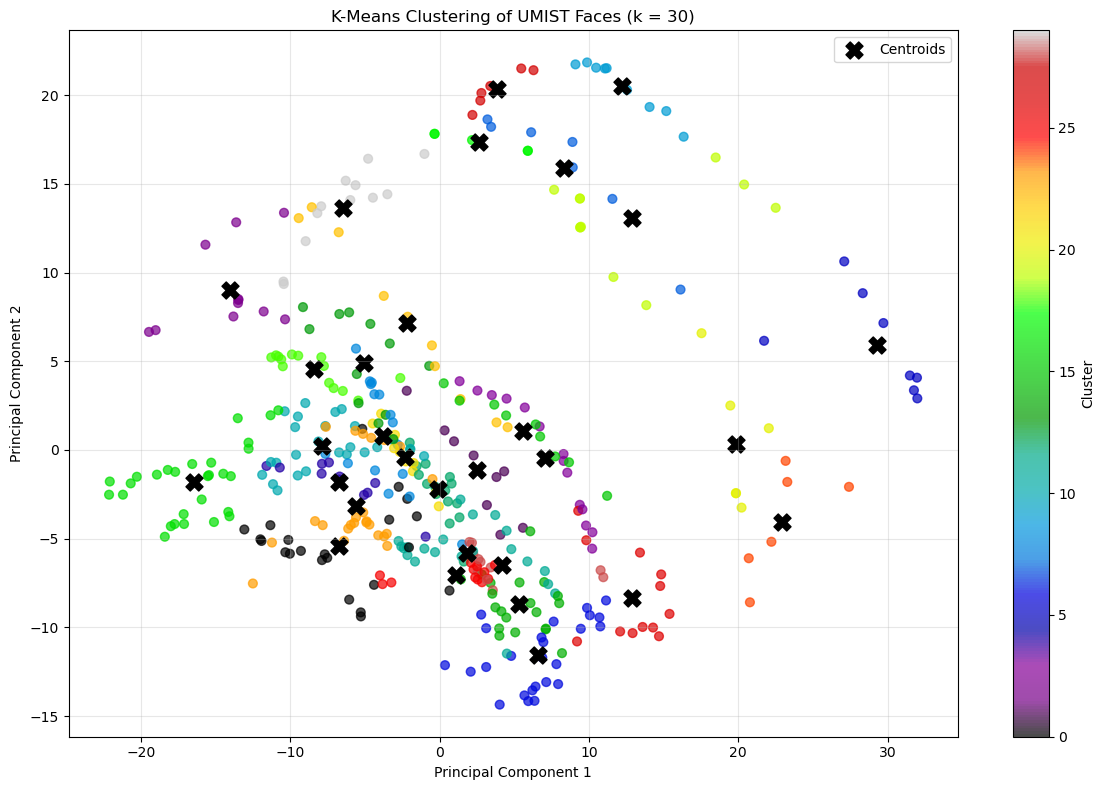

In [24]:
#2D K-means cluster visualization 
plt.figure(figsize=(12, 8))


scatter = plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=kmeans_labels,
    cmap="nipy_spectral",
    s=40,
    alpha=0.7
)


# Plot K-Means centroids
centroids = (best_kmeans.cluster_centers_)


plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=150,
    c="black",
    label="Centroids"
)


plt.title(f"K-Means Clustering of UMIST Faces (k = {best_k})")

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()


plt.savefig(
    "kmeans_2d_clusters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Selected clusters: [16, 6, 10, 23]


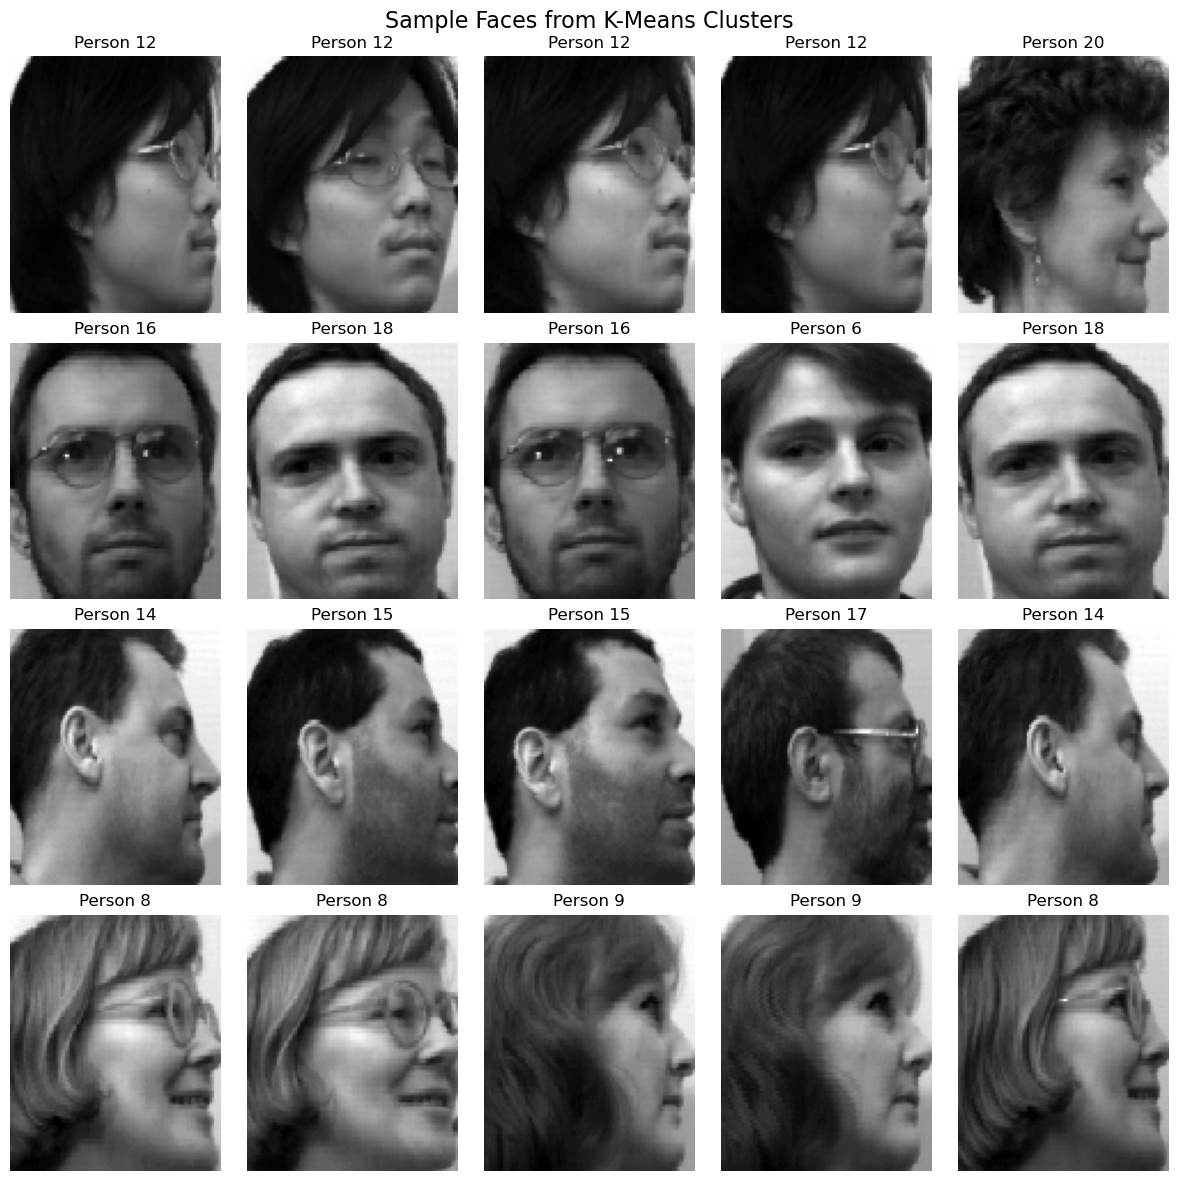

In [25]:

#Displaying sample faces from the k-means clusters 
# Find the four largest clusters
cluster_sizes = pd.Series(
    kmeans_labels
).value_counts()


selected_clusters = (
    cluster_sizes
    .head(4)
    .index
    .tolist()
)


print(
    "Selected clusters:",
    selected_clusters
)


# Original training images
X_train_images = (
    X_train.to_numpy()
)


fig, axes = plt.subplots(
    len(selected_clusters),
    5,
    figsize=(12, 3 * len(selected_clusters))
)


for row, cluster in enumerate(
    selected_clusters
):

    cluster_indices = np.where(
        kmeans_labels == cluster
    )[0]


    # Show up to 5 images
    sample_indices = (
        cluster_indices[:5]
    )


    for col in range(5):

        ax = axes[
            row,
            col
        ]


        if col < len(
            sample_indices
        ):

            index = sample_indices[
                col
            ]


            image = (
                X_train_images[index]
                .reshape(112, 92)
            )


            person = (
                y_train_array[index]
            )


            ax.imshow(
                image,
                cmap="gray"
            )


            ax.set_title(
                f"Person {person}"
            )


        ax.axis("off")


    axes[row, 0].set_ylabel(
        f"Cluster {cluster}",
        fontsize=12
    )


plt.suptitle("Sample Faces from K-Means Clusters",fontsize=16)

plt.tight_layout()


plt.savefig(
    "kmeans_cluster_faces.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
#Hierarchical Clustering
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering

from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

from scipy.cluster.hierarchy import (
    linkage,
    dendrogram
)

print("Training data shape:", X_train_pca.shape)
print("Training labels shape:", y_train.shape)

print("Number of actual people:", y_train.nunique())

Training data shape: (402, 100)
Training labels shape: (402,)
Number of actual people: 20


In [28]:
linkage_methods = [
    "ward",
    "complete",
    "average"
]

cluster_range = range(2, 31)

hierarchical_results = []


# Convert actual labels into NumPy array
y_train_array = y_train.to_numpy()


# Purity calculation
def calculate_purity(true_labels, cluster_labels):

    total_correct = 0

    for cluster in np.unique(cluster_labels):

        people = true_labels[
            cluster_labels == cluster
        ]

        unique_people, counts = np.unique(
            people,
            return_counts=True
        )

        total_correct += counts.max()

    return total_correct / len(true_labels)


# Test each linkage method
for method in linkage_methods:

    print("\nLinkage method:", method)

    for k in cluster_range:

        # Create clustering model
        hierarchical_model = AgglomerativeClustering(
            n_clusters=k,
            linkage=method
        )

        # Perform clustering
        cluster_labels = hierarchical_model.fit_predict(
            X_train_pca
        )

        # Calculate evaluation metrics
        silhouette = silhouette_score(
            X_train_pca,
            cluster_labels
        )

        purity = calculate_purity(
            y_train_array,
            cluster_labels
        )

        ari = adjusted_rand_score(
            y_train_array,
            cluster_labels
        )

        nmi = normalized_mutual_info_score(
            y_train_array,
            cluster_labels
        )

        # Save results
        hierarchical_results.append({

            "Linkage": method,

            "Clusters": k,

            "Silhouette": silhouette,

            "Purity": purity,

            "ARI": ari,

            "NMI": nmi

        })

        print(
            f"k = {k:2d} | "
            f"Silhouette = {silhouette:.4f} | "
            f"Purity = {purity:.4f}"
        )


# Convert results into DataFrame
hierarchical_results_df = pd.DataFrame(
    hierarchical_results
)


display(hierarchical_results_df)


Linkage method: ward
k =  2 | Silhouette = 0.2389 | Purity = 0.1517
k =  3 | Silhouette = 0.1220 | Purity = 0.1692
k =  4 | Silhouette = 0.1132 | Purity = 0.2214
k =  5 | Silhouette = 0.1275 | Purity = 0.2214
k =  6 | Silhouette = 0.1350 | Purity = 0.2662
k =  7 | Silhouette = 0.1335 | Purity = 0.3060
k =  8 | Silhouette = 0.1450 | Purity = 0.3308
k =  9 | Silhouette = 0.1542 | Purity = 0.3557
k = 10 | Silhouette = 0.1656 | Purity = 0.3806
k = 11 | Silhouette = 0.1695 | Purity = 0.4129
k = 12 | Silhouette = 0.1735 | Purity = 0.4204
k = 13 | Silhouette = 0.1646 | Purity = 0.4229
k = 14 | Silhouette = 0.1613 | Purity = 0.4478
k = 15 | Silhouette = 0.1663 | Purity = 0.4627
k = 16 | Silhouette = 0.1744 | Purity = 0.4726
k = 17 | Silhouette = 0.1794 | Purity = 0.4900
k = 18 | Silhouette = 0.1887 | Purity = 0.5124
k = 19 | Silhouette = 0.1953 | Purity = 0.5274
k = 20 | Silhouette = 0.2003 | Purity = 0.5323
k = 21 | Silhouette = 0.2060 | Purity = 0.5498
k = 22 | Silhouette = 0.2128 | Purity 

,Linkage,Clusters,Silhouette,Purity,ARI,NMI
0,ward,2,0.238918,0.151741,0.023897,0.189703
1,ward,3,0.121958,0.169154,0.051513,0.262520
2,ward,4,0.113214,0.221393,0.127296,0.402277
3,ward,5,0.127536,0.221393,0.113513,0.395988
4,ward,6,0.134973,0.266169,0.170158,0.474220
...,...,...,...,...,...,...
82,average,26,0.197189,0.534826,0.353734,0.700642
83,average,27,0.202934,0.554726,0.346126,0.701076
84,average,28,0.202920,0.567164,0.369003,0.703195
85,average,29,0.203895,0.582090,0.372196,0.709584


In [29]:
best_hierarchical_results = (
    hierarchical_results_df
    .loc[
        hierarchical_results_df
        .groupby("Linkage")["Silhouette"]
        .idxmax()
    ]
    .reset_index(drop=True)
)

print("Best results for each linkage method:")
print("=" * 70)

display(best_hierarchical_results)

Best results for each linkage method:


,Linkage,Clusters,Silhouette,Purity,ARI,NMI
0,average,2,0.319083,0.104478,0.000234,0.037131
1,complete,2,0.239910,0.136816,0.016166,0.152433
2,ward,30,0.243967,0.686567,0.417849,0.738424


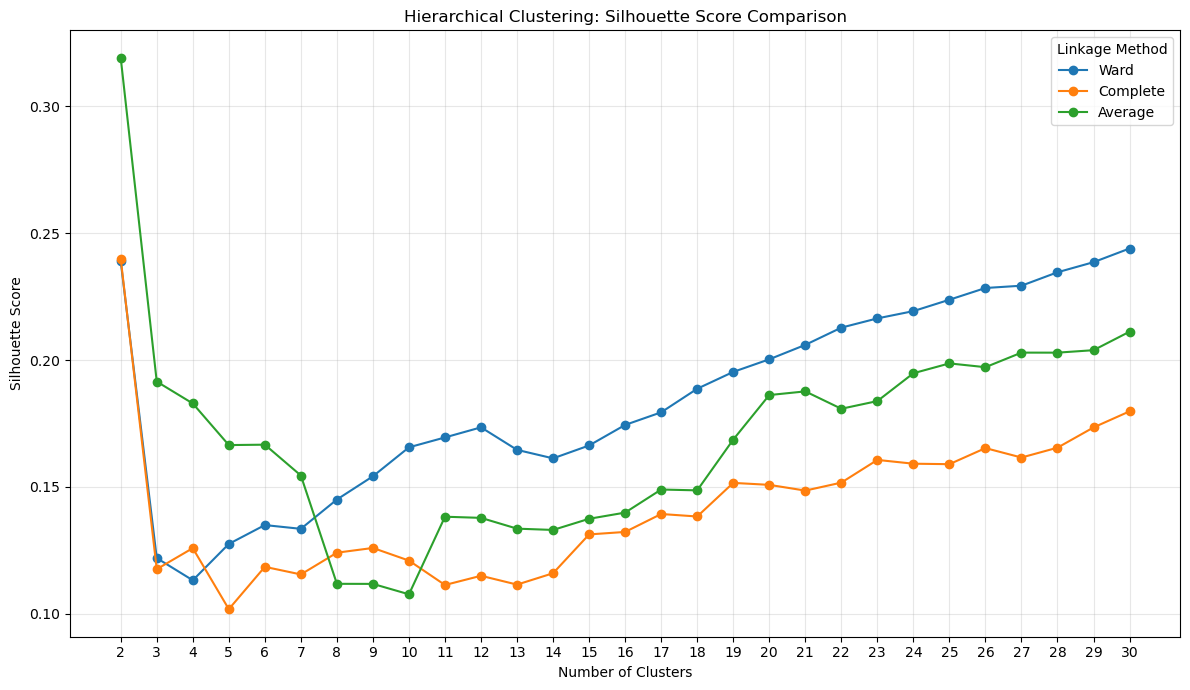

In [30]:

#Comparing silhoutte scores 
plt.figure(figsize=(12, 7))

for method in linkage_methods:

    method_results = hierarchical_results_df[
        hierarchical_results_df["Linkage"] == method
    ]

    plt.plot(
        method_results["Clusters"],
        method_results["Silhouette"],
        marker="o",
        label=method.capitalize()
    )


plt.title("Hierarchical Clustering: Silhouette Score Comparison")

plt.xlabel("Number of Clusters")

plt.ylabel("Silhouette Score")

plt.xticks(list(cluster_range))

plt.legend(title="Linkage Method")

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "hierarchical_silhouette_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

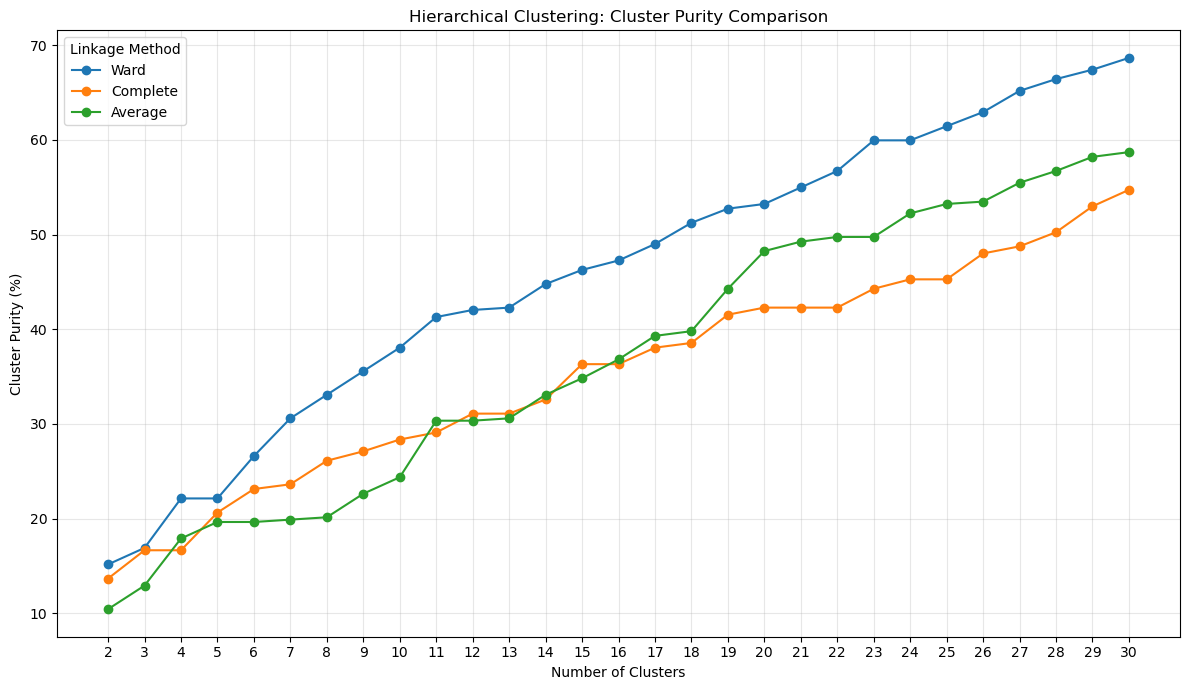

In [31]:

#compare cluster purity
plt.figure(figsize=(12, 7))

for method in linkage_methods:

    method_results = hierarchical_results_df[
        hierarchical_results_df["Linkage"] == method
    ]

    plt.plot(
        method_results["Clusters"],
        method_results["Purity"] * 100,
        marker="o",
        label=method.capitalize()
    )


plt.title("Hierarchical Clustering: Cluster Purity Comparison")

plt.xlabel("Number of Clusters")

plt.ylabel("Cluster Purity (%)")

plt.xticks(list(cluster_range))

plt.legend(title="Linkage Method")

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "hierarchical_purity_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Ward linkage matrix shape: (401, 4)


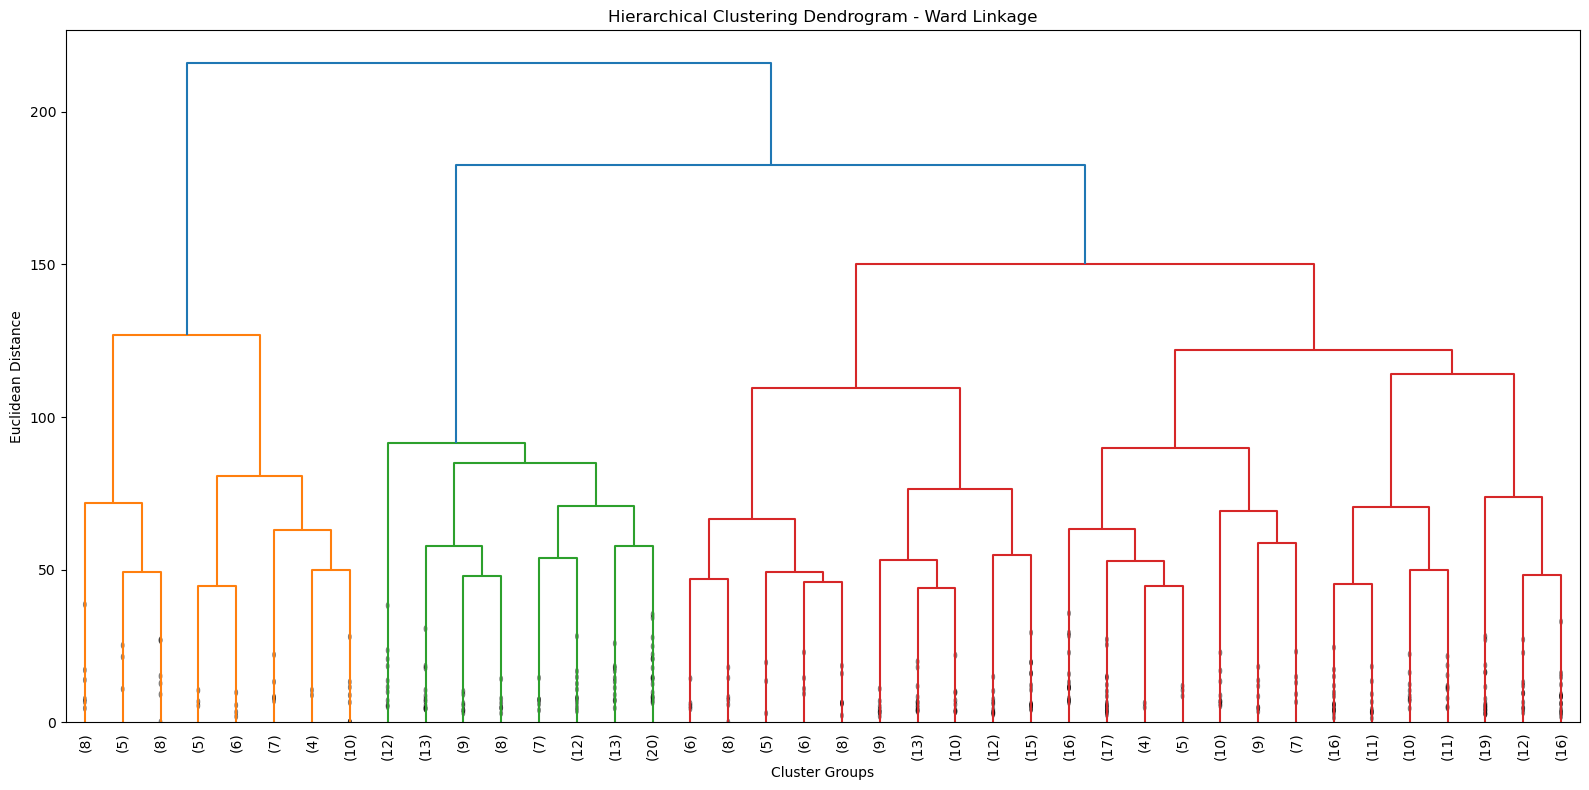

In [32]:

#Wardlinkage dendrogram 
# Calculate hierarchical linkage matrix
ward_linkage_matrix = linkage(
    X_train_pca,
    method="ward",
    metric="euclidean"
)

print(
    "Ward linkage matrix shape:",
    ward_linkage_matrix.shape
)


plt.figure(figsize=(16, 8))

dendrogram(
    ward_linkage_matrix,
    truncate_mode="lastp",
    p=40,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True
)

plt.title("Hierarchical Clustering Dendrogram - Ward Linkage")

plt.xlabel("Cluster Groups")

plt.ylabel("Euclidean Distance")

plt.tight_layout()

plt.savefig(
    "ward_dendrogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

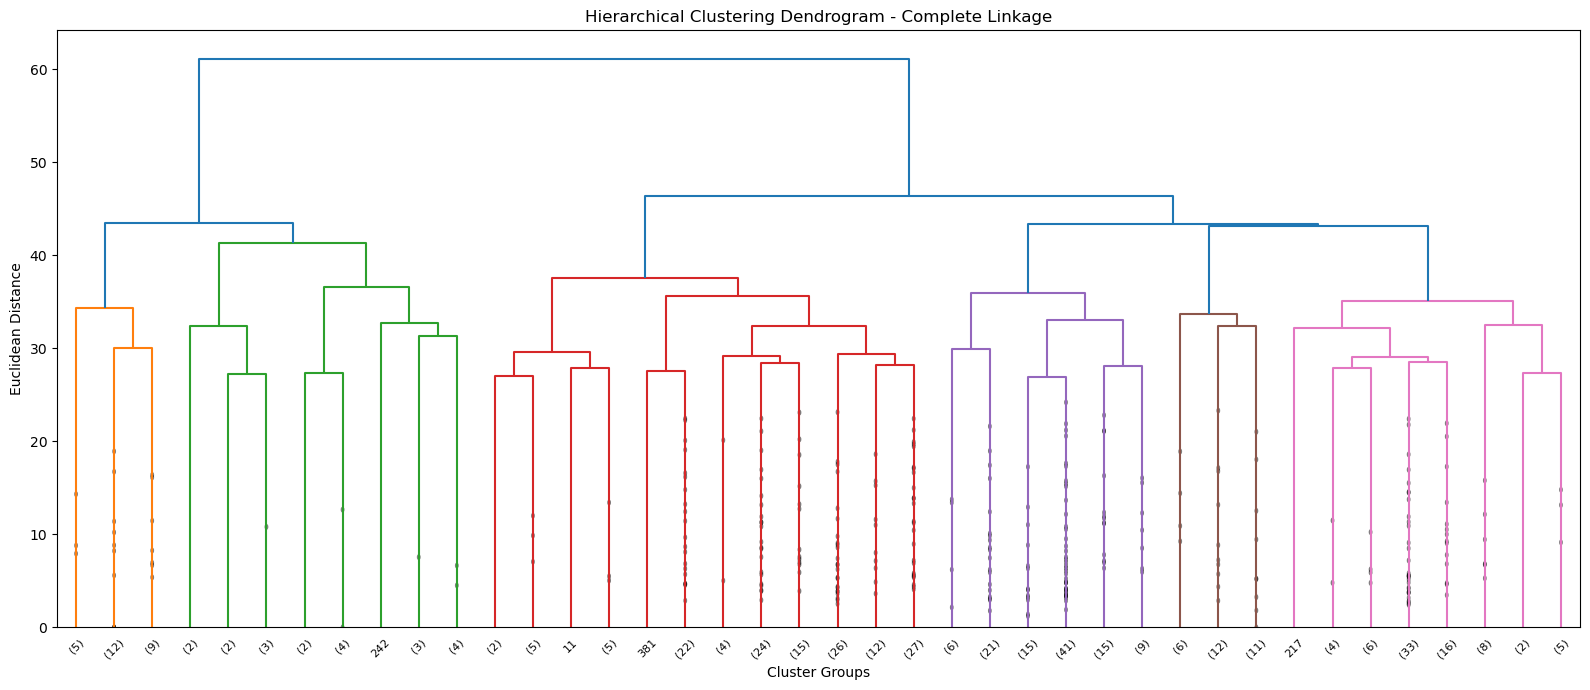

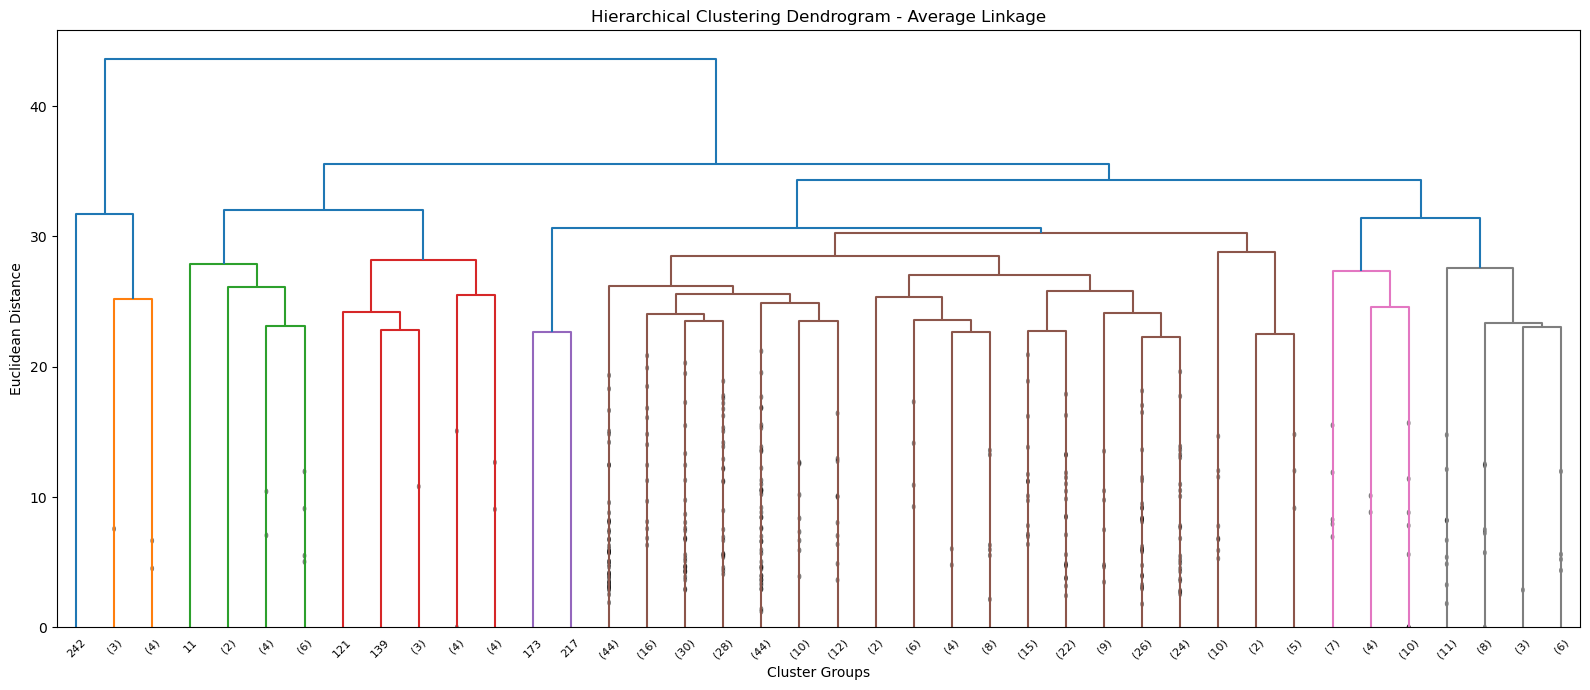

In [33]:

#Complete and average dendrograms
#Complete linkage
complete_linkage_matrix = linkage(
    X_train_pca,
    method="complete",
    metric="euclidean"
)

plt.figure(figsize=(16, 7))

dendrogram(
    complete_linkage_matrix,
    truncate_mode="lastp",
    p=40,
    show_contracted=True
)

plt.title("Hierarchical Clustering Dendrogram - Complete Linkage")

plt.xlabel("Cluster Groups")

plt.ylabel("Euclidean Distance")

plt.tight_layout()

plt.savefig(
    "complete_dendrogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Average linkage
average_linkage_matrix = linkage(
    X_train_pca,
    method="average",
    metric="euclidean"
)

plt.figure(figsize=(16, 7))

dendrogram(
    average_linkage_matrix,
    truncate_mode="lastp",
    p=40,
    show_contracted=True
)

plt.title("Hierarchical Clustering Dendrogram - Average Linkage")

plt.xlabel("Cluster Groups")

plt.ylabel("Euclidean Distance")

plt.tight_layout()

plt.savefig(
    "average_dendrogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
#Automatically select final hierarchical model
#Select Ward's best result
ward_best = best_hierarchical_results[
    best_hierarchical_results["Linkage"] == "ward"
].iloc[0]

final_linkage = "ward"

final_hierarchical_k = int(
    ward_best["Clusters"]
)

print("Selected linkage:", final_linkage)

print("Selected number of clusters:", final_hierarchical_k)

print(
    "Silhouette score:",
    round(ward_best["Silhouette"], 4)
)

print(
    "Purity:",
    round(ward_best["Purity"], 4)
)

print(
    "ARI:",
    round(ward_best["ARI"], 4)
)

print(
    "NMI:",
    round(ward_best["NMI"], 4)
)

Selected linkage: ward
Selected number of clusters: 30
Silhouette score: 0.244
Purity: 0.6866
ARI: 0.4178
NMI: 0.7384


In [38]:

#Final hierarchical clusterin model
best_hierarchical_model = AgglomerativeClustering(
    n_clusters=final_hierarchical_k,
    linkage=final_linkage
)

hierarchical_labels = (
    best_hierarchical_model.fit_predict(
        X_train_pca
    )
)


print("Linkage method:",final_linkage)

print("Number of clusters:", final_hierarchical_k)

print(
    "Silhouette score:",
    round(
        silhouette_score(
            X_train_pca,
            hierarchical_labels
        ),
        4
    )
)

print(
    "Cluster purity:",
    round(
        calculate_purity(
            y_train_array,
            hierarchical_labels
        ),
        4
    )
)

print(
    "Adjusted Rand Index:",
    round(
        adjusted_rand_score(
            y_train_array,
            hierarchical_labels
        ),
        4
    )
)

print(
    "Normalized Mutual Information:",
    round(
        normalized_mutual_info_score(
            y_train_array,
            hierarchical_labels
        ),
        4
    )
)

Linkage method: ward
Number of clusters: 30
Silhouette score: 0.244
Cluster purity: 0.6866
Adjusted Rand Index: 0.4178
Normalized Mutual Information: 0.7384


In [39]:

#Hierarchical cluster composition 
hierarchical_cluster_results = pd.DataFrame({

    "Person": y_train_array,

    "Cluster": hierarchical_labels

})


hierarchical_composition = pd.crosstab(hierarchical_cluster_results["Cluster"], hierarchical_cluster_results["Person"])



display(hierarchical_composition)

Person,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Cluster,,,,,,,,,,,,,,,,,,,,
0,0,2,1,8,0,0,0,0,0,8,0,0,0,0,0,0,0,0,0,0
1,1,5,7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,17,0,0
3,0,0,0,0,0,0,8,0,0,0,0,15,0,0,0,0,0,0,0,5
4,0,0,0,0,0,0,0,0,0,5,4,0,0,0,0,0,0,0,0,0
5,11,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,0,0,0,6,5,2,10,0,0,0
7,0,0,0,0,6,0,0,13,8,0,0,0,0,0,0,0,0,0,0,0
8,0,8,6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [40]:
#Hiearchical Cluster summary 
hierarchical_summary = []


for cluster in sorted(
    np.unique(hierarchical_labels)
):

    mask = (
        hierarchical_labels == cluster
    )

    people = y_train_array[
        mask
    ]

    unique_people, counts = np.unique(
        people,
        return_counts=True
    )

    dominant_index = np.argmax(
        counts
    )

    dominant_person = unique_people[
        dominant_index
    ]

    dominant_count = counts[
        dominant_index
    ]

    cluster_size = len(
        people
    )

    cluster_purity = (
        dominant_count
        / cluster_size
    )


    hierarchical_summary.append({

        "Cluster": cluster,

        "Size": cluster_size,

        "Dominant Person": dominant_person,

        "Dominant Images": dominant_count,

        "Cluster Purity": cluster_purity

    })


hierarchical_summary_df = pd.DataFrame(
    hierarchical_summary
)


display(
    hierarchical_summary_df
)


#Save results
hierarchical_summary_df.to_csv("hierarchical_cluster_summary.csv", index=False)

,Cluster,Size,Dominant Person,Dominant Images,Cluster Purity
0,0,19,4,8,0.421053
1,1,13,3,7,0.538462
2,2,17,18,17,1.000000
3,3,28,12,15,0.535714
4,4,9,10,5,0.555556
5,5,11,1,11,1.000000
6,6,23,17,10,0.434783
7,7,27,8,13,0.481481
8,8,14,2,8,0.571429
9,9,16,10,9,0.562500


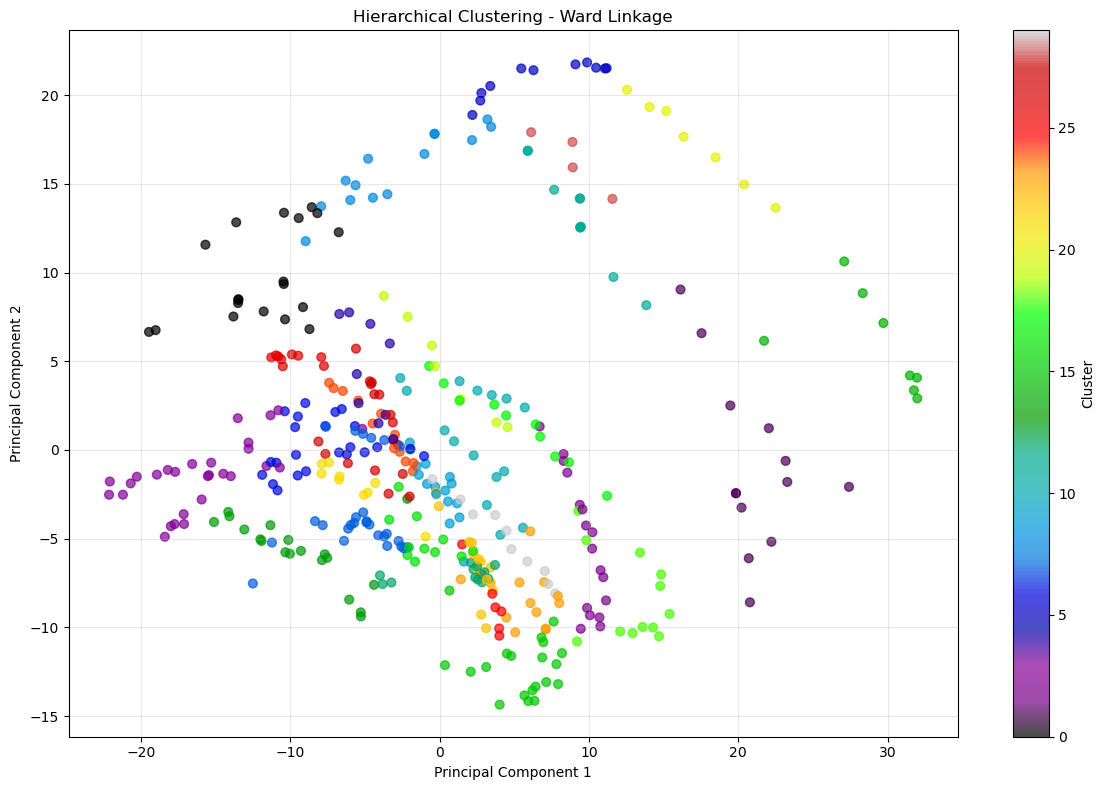

In [41]:
#2D Hierarchical cluster visualization
plt.figure(figsize=(12, 8))


scatter = plt.scatter(

    X_train_pca[:, 0],

    X_train_pca[:, 1],

    c=hierarchical_labels,

    cmap="nipy_spectral",

    s=40,

    alpha=0.7

)


plt.title(f"Hierarchical Clustering - {final_linkage.capitalize()} Linkage")

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")


plt.colorbar(
    scatter,
    label="Cluster"
)


plt.grid(
    True,
    alpha=0.3
)


plt.tight_layout()


plt.savefig(
    "hierarchical_2d_clusters.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

Selected clusters: [3, 7, 6, 15]


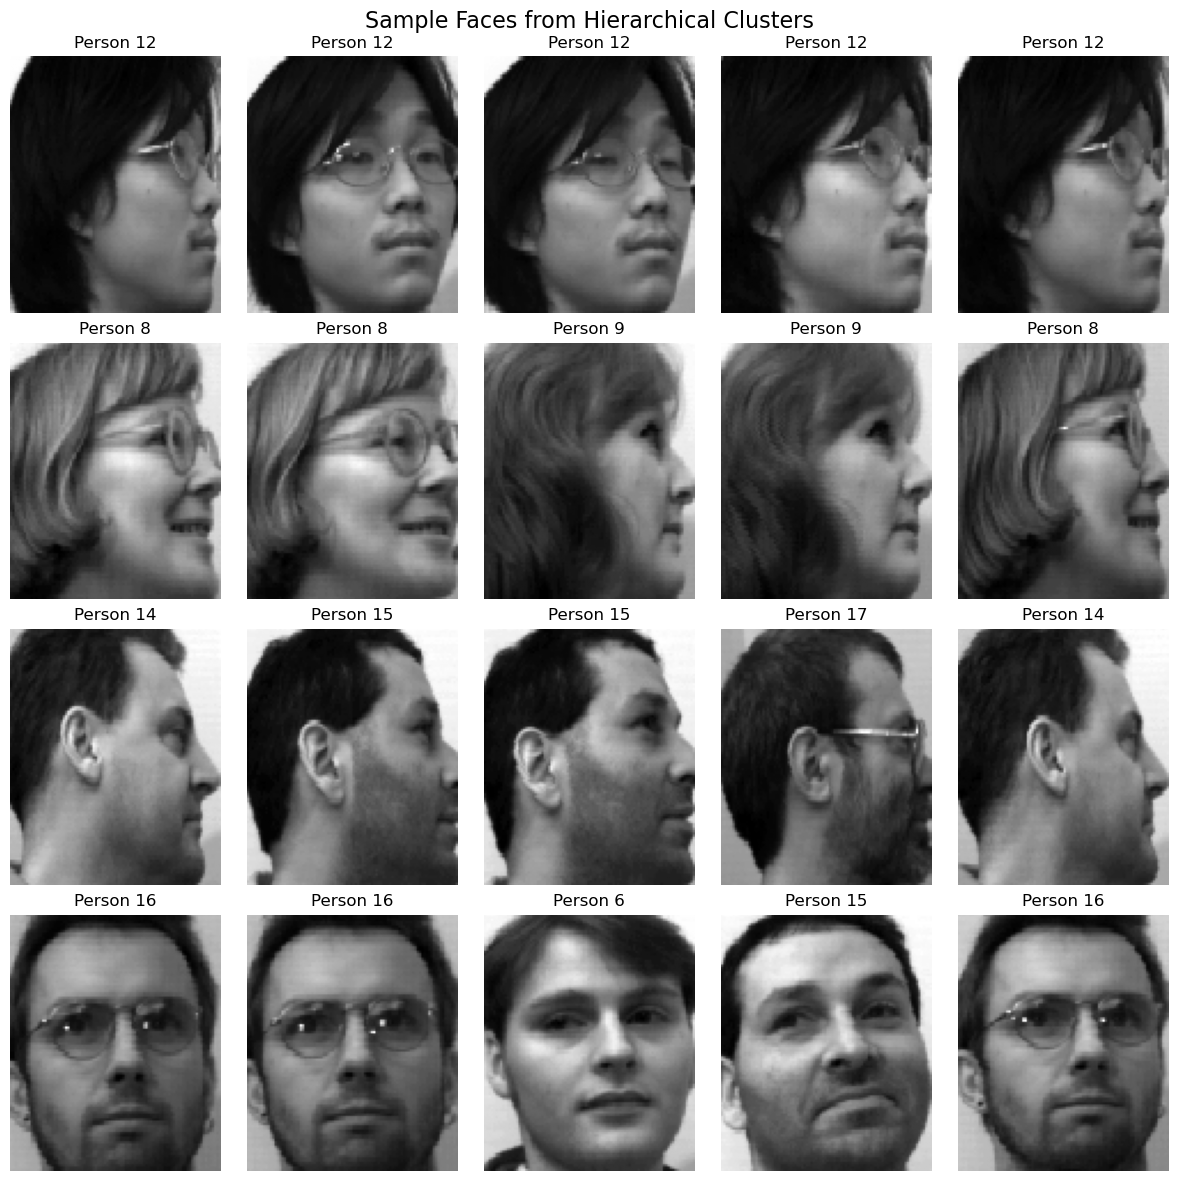

In [42]:

#Identify four largest clusters
hierarchical_cluster_sizes = pd.Series(
    hierarchical_labels
).value_counts()


selected_hierarchical_clusters = (
    hierarchical_cluster_sizes
    .head(4)
    .index
    .tolist()
)


print(
    "Selected clusters:",
    selected_hierarchical_clusters
)


# Original training images
X_train_images = X_train.to_numpy()


fig, axes = plt.subplots(

    len(selected_hierarchical_clusters),

    5,

    figsize=(
        12,
        3 * len(selected_hierarchical_clusters)
    )

)


for row, cluster in enumerate(
    selected_hierarchical_clusters
):

    cluster_indices = np.where(
        hierarchical_labels == cluster
    )[0]


    sample_indices = cluster_indices[:5]


    for col in range(5):

        ax = axes[row, col]


        if col < len(sample_indices):

            index = sample_indices[col]


            image = X_train_images[index].reshape(
                112,
                92
            )


            person = y_train_array[index]


            ax.imshow(
                image,
                cmap="gray"
            )


            ax.set_title(
                f"Person {person}"
            )


        ax.axis("off")


    axes[row, 0].set_ylabel(
        f"Cluster {cluster}",
        fontsize=12
    )


plt.suptitle(
    "Sample Faces from Hierarchical Clusters",
    fontsize=16
)


plt.tight_layout()


plt.savefig(
    "hierarchical_cluster_faces.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [43]:
#K means vs hiearchical clustering 
clustering_comparison = pd.DataFrame({

    "Algorithm": [
        "K-Means",
        "Hierarchical"
    ],

    "Number of Clusters": [
        best_k,
        final_hierarchical_k
    ],

    "Silhouette Score": [
        silhouette_score(
            X_train_pca,
            kmeans_labels
        ),

        silhouette_score(
            X_train_pca,
            hierarchical_labels
        )
    ],

    "Purity": [
        calculate_purity(
            y_train_array,
            kmeans_labels
        ),

        calculate_purity(
            y_train_array,
            hierarchical_labels
        )
    ],

    "ARI": [
        adjusted_rand_score(
            y_train_array,
            kmeans_labels
        ),

        adjusted_rand_score(
            y_train_array,
            hierarchical_labels
        )
    ],

    "NMI": [
        normalized_mutual_info_score(
            y_train_array,
            kmeans_labels
        ),

        normalized_mutual_info_score(
            y_train_array,
            hierarchical_labels
        )
    ]

})


display(clustering_comparison.round(4))


clustering_comparison.to_csv(
    "clustering_algorithm_comparison.csv",
    index=False
)

,Algorithm,Number of Clusters,Silhouette Score,Purity,ARI,NMI
0,K-Means,30,0.2388,0.6368,0.3597,0.7069
1,Hierarchical,30,0.2440,0.6866,0.4178,0.7384
